# Customer Churn Prediction — Simple Machine Learning Project

**Goal:** Predict whether a telecom customer will leave (Churn = Yes) using four classification algorithms: KNN, Naive Bayes, SVM, and Decision Tree.

> This notebook uses straightforward code and short explanations. Run cells from top to bottom.


## 1. Load and Inspect the Dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')

print(df.shape)
df.info()


(7043, 21)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null

In [2]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [4]:
# Convert TotalCharges to numbers; blank entries become NaN
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

# Fill missing values with the median
df['TotalCharges'] = df['TotalCharges'].fillna(df['TotalCharges'].median())

# Check the Churn distribution
df['Churn'].value_counts()


Churn
No     5174
Yes    1869
Name: count, dtype: int64

## 2. Exploratory Data Analysis (EDA)

### 2.1 Univariate Analysis

c:\Users\giris\AppData\Local\Programs\Python\Python311\Lib\site-packages\seaborn\categorical.py:1273: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(aggregator, agg_var)


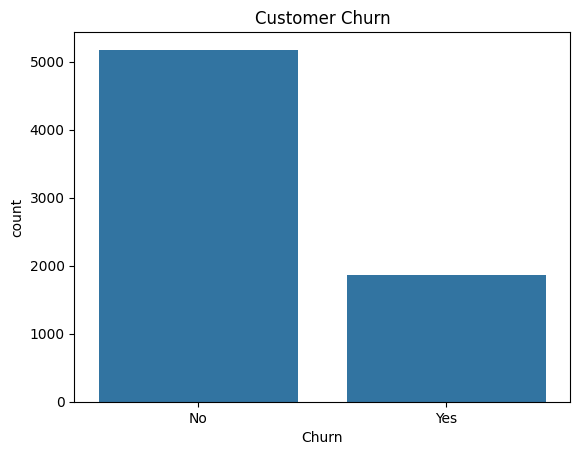

In [5]:
sns.countplot(x='Churn', data=df)
plt.title('Customer Churn')
plt.show()


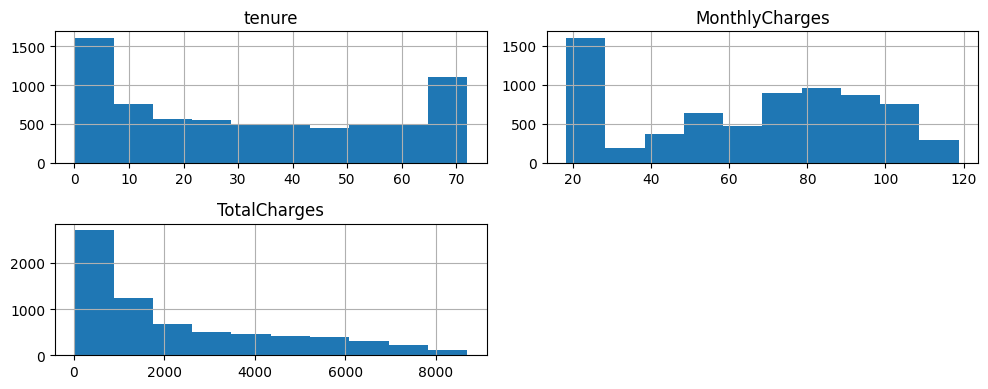

In [6]:
# Histograms for numerical columns
df[['tenure', 'MonthlyCharges', 'TotalCharges']].hist(figsize=(10, 4))
plt.tight_layout()
plt.show()


c:\Users\giris\AppData\Local\Programs\Python\Python311\Lib\site-packages\seaborn\categorical.py:1273: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(aggregator, agg_var)
c:\Users\giris\AppData\Local\Programs\Python\Python311\Lib\site-packages\seaborn\categorical.py:1273: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(aggregator, agg_var)
c:\Users\giris\AppData\Local\Programs\Python\Python311\Lib\site-pack

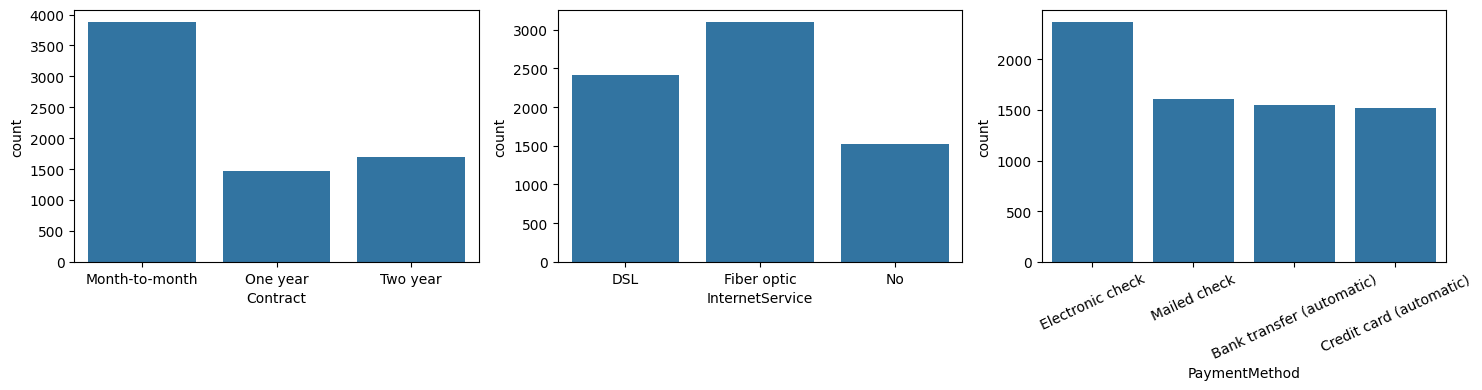

In [7]:
# Countplots for categorical columns
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.countplot(x='Contract', data=df, ax=axes[0])
sns.countplot(x='InternetService', data=df, ax=axes[1])
sns.countplot(x='PaymentMethod', data=df, ax=axes[2])
axes[2].tick_params(axis='x', rotation=25)
plt.tight_layout()
plt.show()


### 2.2 Bivariate Analysis

c:\Users\giris\AppData\Local\Programs\Python\Python311\Lib\site-packages\seaborn\_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
c:\Users\giris\AppData\Local\Programs\Python\Python311\Lib\site-packages\seaborn\categorical.py:1273: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(aggregator, agg_var)
c:\Users\giris\AppData\Local\Programs\Python\Python311\Lib\site-packages\seaborn\_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to ge

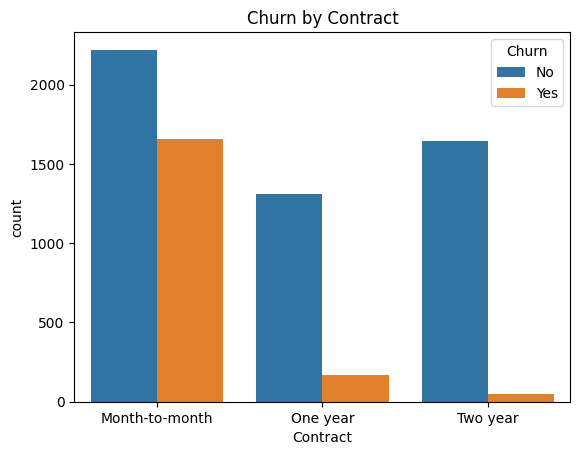

In [8]:
# Churn across contract types
sns.countplot(x='Contract', hue='Churn', data=df)
plt.title('Churn by Contract')
plt.show()


In [9]:
# Churn rate for each contract type (percentage)
df.groupby('Contract')['Churn'].apply(lambda x: (x == 'Yes').mean() * 100)


Contract
Month-to-month    42.709677
One year          11.269518
Two year           2.831858
Name: Churn, dtype: float64

c:\Users\giris\AppData\Local\Programs\Python\Python311\Lib\site-packages\seaborn\categorical.py:1273: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(aggregator, agg_var)


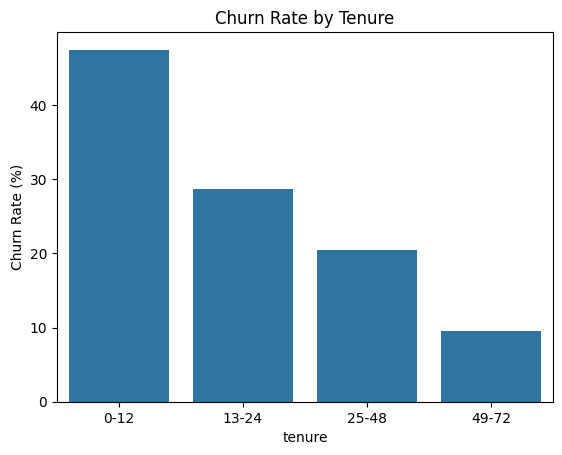

In [10]:
# Churn by tenure groups
tenure_bins = pd.cut(df['tenure'], bins=[-1, 12, 24, 48, 72],
                     labels=['0-12', '13-24', '25-48', '49-72'])
tenure_churn = df.groupby(tenure_bins, observed=False)['Churn'].apply(
    lambda x: (x == 'Yes').mean() * 100
).reset_index()

sns.barplot(x='tenure', y='Churn', data=tenure_churn)
plt.ylabel('Churn Rate (%)')
plt.title('Churn Rate by Tenure')
plt.show()


c:\Users\giris\AppData\Local\Programs\Python\Python311\Lib\site-packages\seaborn\categorical.py:632: FutureWarning: SeriesGroupBy.grouper is deprecated and will be removed in a future version of pandas.
  positions = grouped.grouper.result_index.to_numpy(dtype=float)


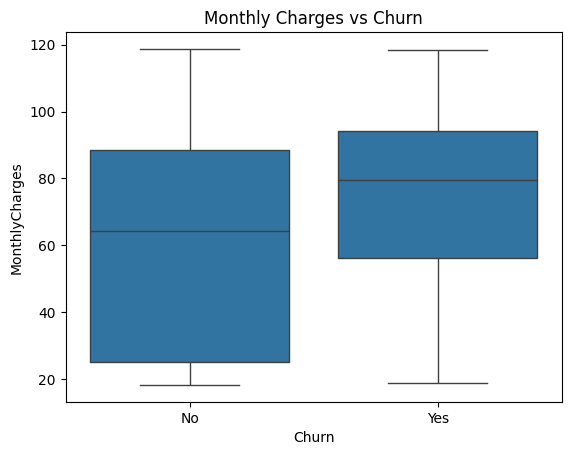

In [11]:
sns.boxplot(x='Churn', y='MonthlyCharges', data=df)
plt.title('Monthly Charges vs Churn')
plt.show()


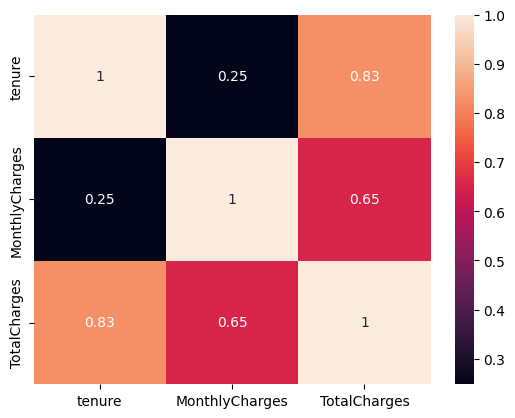

In [12]:
# Correlation of numerical features
corr = df[['tenure', 'MonthlyCharges', 'TotalCharges']].corr()
sns.heatmap(corr, annot=True)
plt.show()


## 3. Prepare the Data

### 3.1 Remove the ID Column and Create Simple Features

In [13]:
# customerID is just an identifier
df = df.drop(columns=['customerID'])

# Group customers by tenure
df['tenure_group'] = pd.cut(df['tenure'], bins=[-1, 12, 36, 60, np.inf],
                            labels=['New', 'Mid', 'Senior', 'Loyal'])

# Count how many add-on services each customer has
services = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
            'TechSupport', 'StreamingTV', 'StreamingMovies']
df['num_services'] = (df[services] == 'Yes').sum(axis=1)

# 1 if they use automatic payment, otherwise 0
df['AutoPay'] = df['PaymentMethod'].apply(
    lambda x: 1 if 'automatic' in str(x).lower() else 0
)


### 3.2 Convert Categories into Numbers

In [14]:
# Convert Yes/No columns to 1/0
binary_cols = ['Partner', 'Dependents', 'PhoneService', 'PaperlessBilling', 'Churn']
for col in binary_cols:
    df[col] = df[col].map({'Yes': 1, 'No': 0})

# Convert gender and MultipleLines
df['gender'] = df['gender'].map({'Female': 0, 'Male': 1})
df['MultipleLines'] = df['MultipleLines'].replace('No phone service', 'No').map({'Yes': 1, 'No': 0})

# Convert tenure group in its natural order
df['tenure_group'] = df['tenure_group'].map(
    {'New': 0, 'Mid': 1, 'Senior': 2, 'Loyal': 3}
)

# Remove service columns used to create num_services
df = df.drop(columns=services)

# Convert remaining categorical columns into dummy columns
df = pd.get_dummies(df, columns=['InternetService', 'Contract', 'PaymentMethod'],
                    drop_first=True, dtype=int)

print(df.shape)


(7043, 21)


### 3.3 Split into Training and Testing Data

We keep 20% of the data for testing. `stratify=y` helps keep the churn/non-churn proportions similar in both sets.

In [15]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=['Churn'])
y = df['Churn']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

print(X_train.shape)
print(X_test.shape)


(5634, 20)
(1409, 20)


### 3.4 Scale Numerical Features

Scaling is especially important for KNN and SVM.

In [16]:
from sklearn.preprocessing import StandardScaler

scale_cols = ['tenure', 'MonthlyCharges', 'TotalCharges', 'num_services']

scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[scale_cols] = scaler.fit_transform(X_train[scale_cols])
X_test_scaled[scale_cols] = scaler.transform(X_test[scale_cols])


### 3.5 Handle Class Imbalance with SMOTE

SMOTE is applied only to the training data, not to the test data.

In [21]:
print(X_train_smote.isnull().sum()[X_train_smote.isnull().sum() > 0])
print(X_train_smote.dtypes)

tenure_group    136
dtype: int64
gender                                      int64
SeniorCitizen                               int64
Partner                                     int64
Dependents                                  int64
tenure                                    float64
PhoneService                                int64
MultipleLines                               int64
PaperlessBilling                            int64
MonthlyCharges                            float64
TotalCharges                              float64
tenure_group                             category
num_services                              float64
AutoPay                                     int64
InternetService_Fiber optic                 int32
InternetService_No                          int32
Contract_One year                           int32
Contract_Two year                           int32
PaymentMethod_Credit card (automatic)       int32
PaymentMethod_Electronic check              int32
PaymentMethod_Mai

In [23]:
# Fill missing values in tenure_group with the mode
X_train_smote['tenure_group'] = X_train_smote['tenure_group'].fillna(
    X_train_smote['tenure_group'].mode()[0]
)
print(X_train_smote.isnull().sum().sum())

0


In [19]:
print("Missing values in X_train_smote:")
print(X_train_smote.isnull().sum().sum())

print("\nMissing values in X_test_scaled:")
print(X_test_scaled.isnull().sum().sum())

Missing values in X_train_smote:
136

Missing values in X_test_scaled:
0


In [24]:
from imblearn.over_sampling import SMOTE

print('Before SMOTE:')
print(y_train.value_counts())

smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train_scaled, y_train)

print('After SMOTE:')
print(pd.Series(y_train_smote).value_counts())


Before SMOTE:
Churn
0    4139
1    1495
Name: count, dtype: int64
After SMOTE:
Churn
0    4139
1    4139
Name: count, dtype: int64


## 4. K-Nearest Neighbours (KNN)

In [27]:
# Fill missing values in tenure_group using its mode
X_train_smote['tenure_group'] = X_train_smote['tenure_group'].fillna(
    X_train_smote['tenure_group'].mode()[0]
)

In [28]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, roc_curve

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_smote, y_train_smote)

y_pred_knn = knn.predict(X_test_scaled)
y_prob_knn = knn.predict_proba(X_test_scaled)[:, 1]

print('Accuracy:', round(accuracy_score(y_test, y_pred_knn), 3))
print('Precision:', round(precision_score(y_test, y_pred_knn), 3))
print('Recall:', round(recall_score(y_test, y_pred_knn), 3))
print('F1:', round(f1_score(y_test, y_pred_knn), 3))
print('AUC:', round(roc_auc_score(y_test, y_prob_knn), 3))


Accuracy: 0.713
Precision: 0.472
Recall: 0.709
F1: 0.567
AUC: 0.776


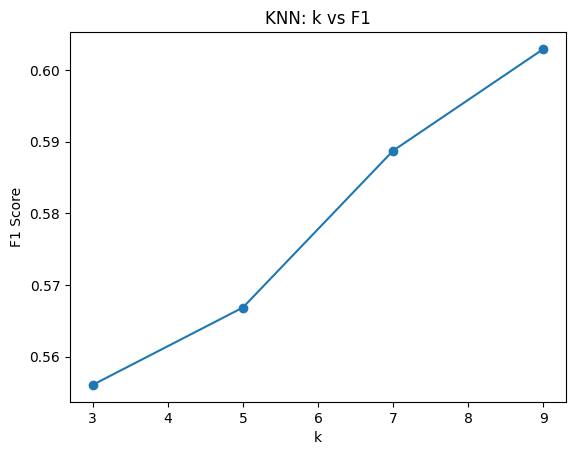

In [29]:
# Try a few values of k and compare their F1 scores
k_values = [3, 5, 7, 9]
f1_scores = []

for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train_smote, y_train_smote)
    pred = model.predict(X_test_scaled)
    f1_scores.append(f1_score(y_test, pred))

plt.plot(k_values, f1_scores, marker='o')
plt.xlabel('k')
plt.ylabel('F1 Score')
plt.title('KNN: k vs F1')
plt.show()


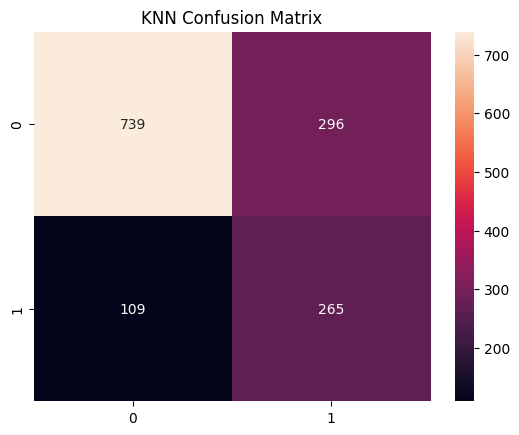

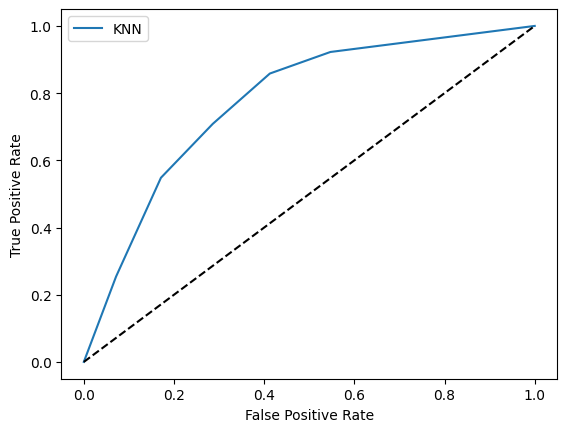

In [30]:
# Confusion matrix
sns.heatmap(confusion_matrix(y_test, y_pred_knn), annot=True, fmt='d')
plt.title('KNN Confusion Matrix')
plt.show()

# ROC curve
fpr_knn, tpr_knn, _ = roc_curve(y_test, y_prob_knn)
plt.plot(fpr_knn, tpr_knn, label='KNN')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()
plt.show()


## 5. Naive Bayes

In [31]:
from sklearn.naive_bayes import GaussianNB

nb = GaussianNB()
nb.fit(X_train_smote, y_train_smote)

y_pred_nb = nb.predict(X_test_scaled)
y_prob_nb = nb.predict_proba(X_test_scaled)[:, 1]

print('Accuracy:', round(accuracy_score(y_test, y_pred_nb), 3))
print('Precision:', round(precision_score(y_test, y_pred_nb), 3))
print('Recall:', round(recall_score(y_test, y_pred_nb), 3))
print('F1:', round(f1_score(y_test, y_pred_nb), 3))
print('AUC:', round(roc_auc_score(y_test, y_prob_nb), 3))


Accuracy: 0.724
Precision: 0.488
Recall: 0.791
F1: 0.603
AUC: 0.817


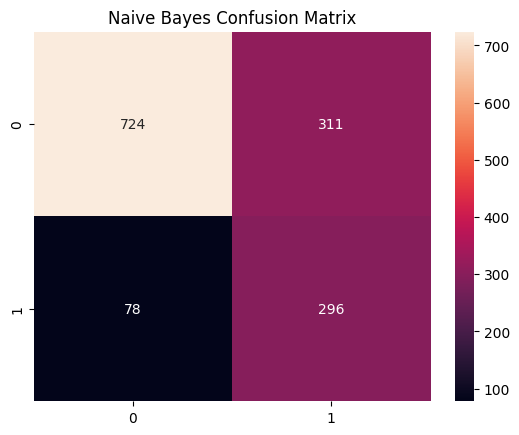

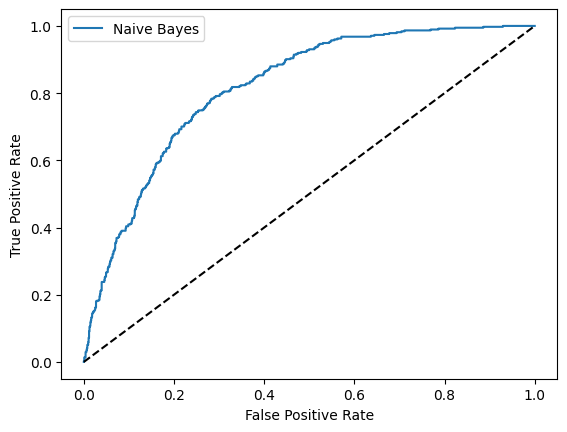

In [32]:
sns.heatmap(confusion_matrix(y_test, y_pred_nb), annot=True, fmt='d')
plt.title('Naive Bayes Confusion Matrix')
plt.show()

fpr_nb, tpr_nb, _ = roc_curve(y_test, y_prob_nb)
plt.plot(fpr_nb, tpr_nb, label='Naive Bayes')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()
plt.show()


## 6. Support Vector Machine (SVM)

In [33]:
from sklearn.svm import SVC

svm = SVC(kernel='rbf', C=1, probability=True, random_state=42)
svm.fit(X_train_smote, y_train_smote)

y_pred_svm = svm.predict(X_test_scaled)
y_prob_svm = svm.predict_proba(X_test_scaled)[:, 1]

print('Accuracy:', round(accuracy_score(y_test, y_pred_svm), 3))
print('Precision:', round(precision_score(y_test, y_pred_svm), 3))
print('Recall:', round(recall_score(y_test, y_pred_svm), 3))
print('F1:', round(f1_score(y_test, y_pred_svm), 3))
print('AUC:', round(roc_auc_score(y_test, y_prob_svm), 3))


Accuracy: 0.745
Precision: 0.513
Recall: 0.765
F1: 0.614
AUC: 0.822


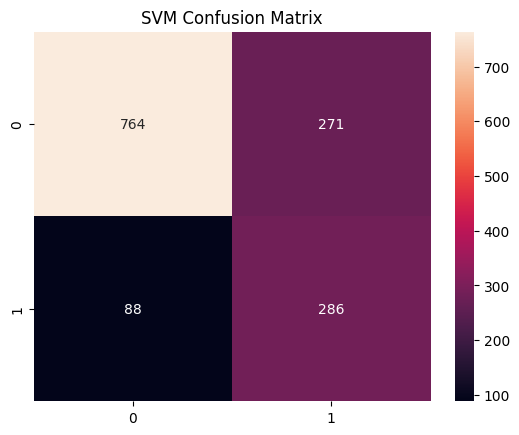

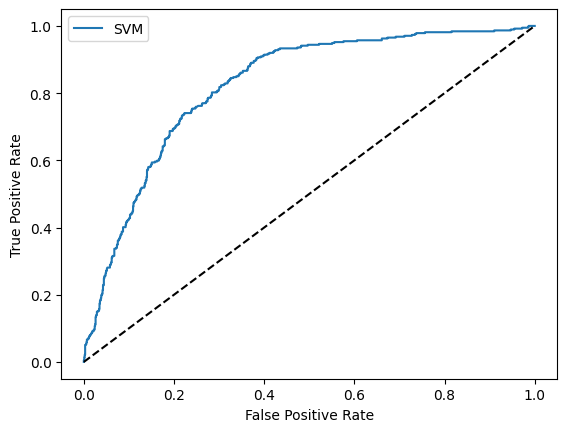

In [34]:
sns.heatmap(confusion_matrix(y_test, y_pred_svm), annot=True, fmt='d')
plt.title('SVM Confusion Matrix')
plt.show()

fpr_svm, tpr_svm, _ = roc_curve(y_test, y_prob_svm)
plt.plot(fpr_svm, tpr_svm, label='SVM')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()
plt.show()


## 7. Decision Tree

In [35]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

dt = DecisionTreeClassifier(max_depth=5, class_weight='balanced', random_state=42)
dt.fit(X_train_scaled, y_train)

y_pred_dt = dt.predict(X_test_scaled)
y_prob_dt = dt.predict_proba(X_test_scaled)[:, 1]

print('Accuracy:', round(accuracy_score(y_test, y_pred_dt), 3))
print('Precision:', round(precision_score(y_test, y_pred_dt), 3))
print('Recall:', round(recall_score(y_test, y_pred_dt), 3))
print('F1:', round(f1_score(y_test, y_pred_dt), 3))
print('AUC:', round(roc_auc_score(y_test, y_prob_dt), 3))


Accuracy: 0.749
Precision: 0.518
Recall: 0.778
F1: 0.622
AUC: 0.829


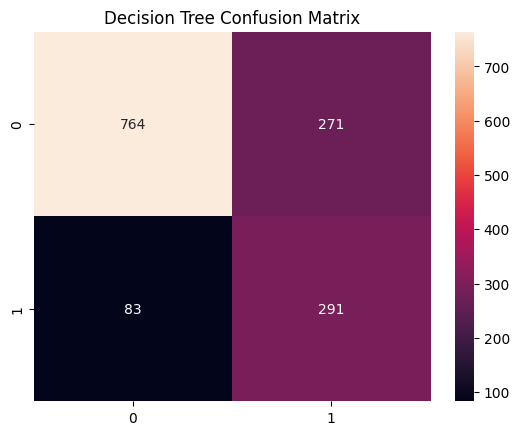

In [36]:
sns.heatmap(confusion_matrix(y_test, y_pred_dt), annot=True, fmt='d')
plt.title('Decision Tree Confusion Matrix')
plt.show()


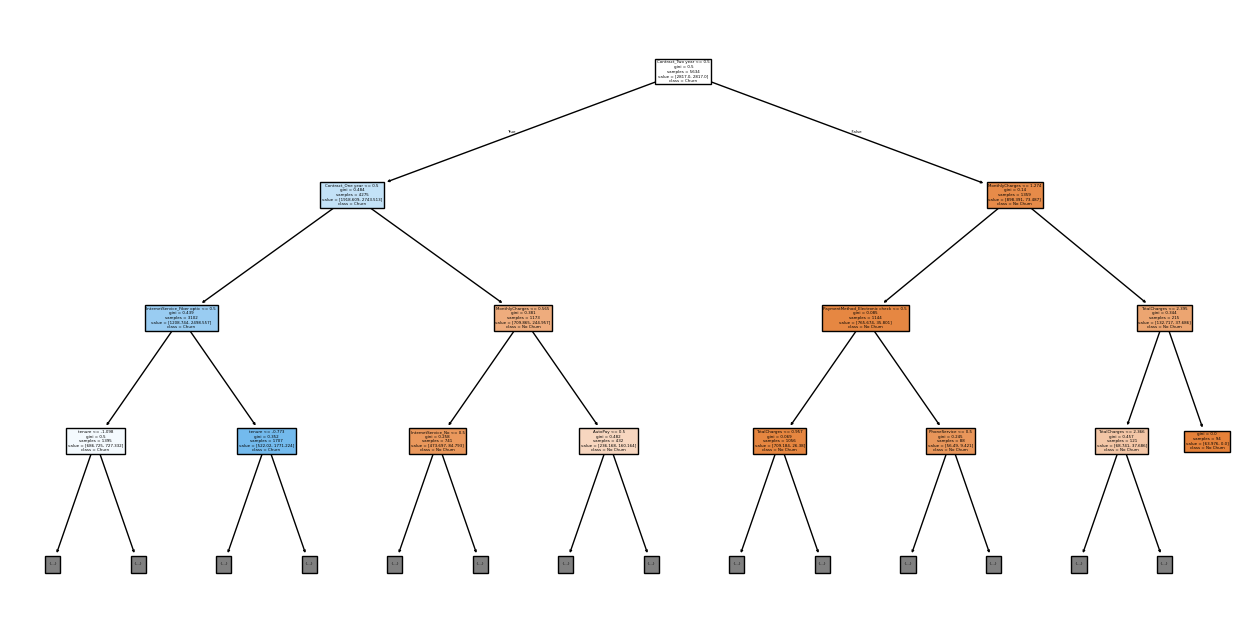

In [37]:
# Show only the first 3 levels so the tree is easy to read
plt.figure(figsize=(16, 8))
plot_tree(dt, max_depth=3, feature_names=X.columns,
          class_names=['No Churn', 'Churn'], filled=True)
plt.show()


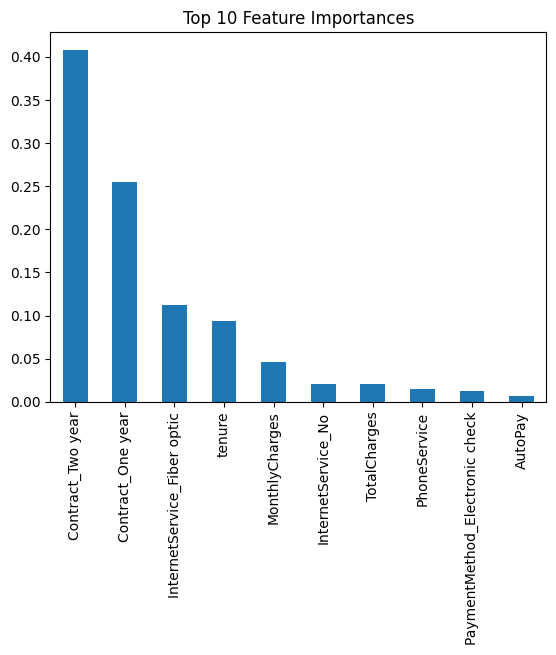

In [38]:
# Which features were most useful for the tree?
importance = pd.Series(dt.feature_importances_, index=X.columns)
importance = importance.sort_values(ascending=False)

importance.head(10).plot(kind='bar')
plt.title('Top 10 Feature Importances')
plt.show()


## 8. Compare the Four Models

In [39]:
# Create a simple table to compare the models
comparison = pd.DataFrame({
    'Model': ['KNN', 'Naive Bayes', 'SVM', 'Decision Tree'],
    'Accuracy': [
        accuracy_score(y_test, y_pred_knn),
        accuracy_score(y_test, y_pred_nb),
        accuracy_score(y_test, y_pred_svm),
        accuracy_score(y_test, y_pred_dt)
    ],
    'Precision': [
        precision_score(y_test, y_pred_knn),
        precision_score(y_test, y_pred_nb),
        precision_score(y_test, y_pred_svm),
        precision_score(y_test, y_pred_dt)
    ],
    'Recall': [
        recall_score(y_test, y_pred_knn),
        recall_score(y_test, y_pred_nb),
        recall_score(y_test, y_pred_svm),
        recall_score(y_test, y_pred_dt)
    ],
    'F1': [
        f1_score(y_test, y_pred_knn),
        f1_score(y_test, y_pred_nb),
        f1_score(y_test, y_pred_svm),
        f1_score(y_test, y_pred_dt)
    ],
    'AUC': [
        roc_auc_score(y_test, y_prob_knn),
        roc_auc_score(y_test, y_prob_nb),
        roc_auc_score(y_test, y_prob_svm),
        roc_auc_score(y_test, y_prob_dt)
    ]
})

comparison.sort_values('Recall', ascending=False)


,Model,Accuracy,Precision,Recall,F1,AUC
1,Naive Bayes,0.723918,0.487644,0.791444,0.603466,0.816714
3,Decision Tree,0.748758,0.517794,0.778075,0.621795,0.828735
2,SVM,0.745209,0.513465,0.764706,0.614393,0.822462
0,KNN,0.712562,0.472371,0.708556,0.566845,0.775544


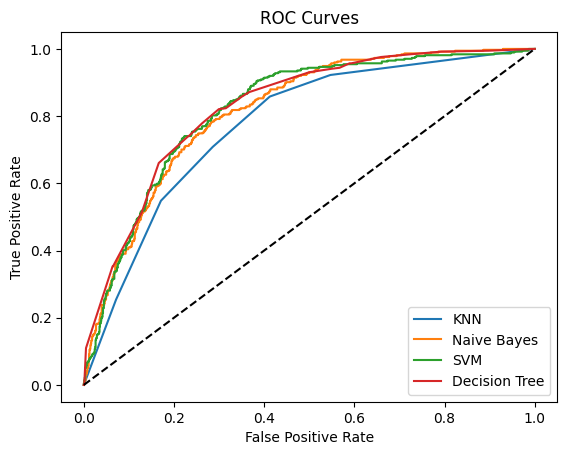

In [40]:
# Plot all model ROC curves together
plt.plot(fpr_knn, tpr_knn, label='KNN')
plt.plot(fpr_nb, tpr_nb, label='Naive Bayes')
plt.plot(fpr_svm, tpr_svm, label='SVM')
fpr_dt, tpr_dt, _ = roc_curve(y_test, y_prob_dt)
plt.plot(fpr_dt, tpr_dt, label='Decision Tree')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves')
plt.legend()
plt.show()


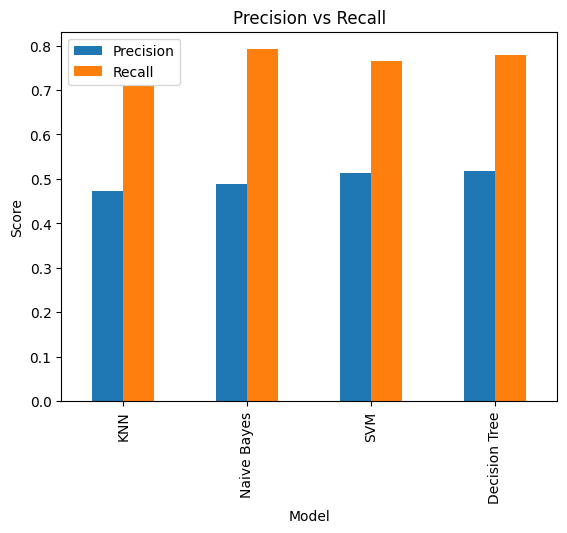

In [41]:
# Compare precision and recall
comparison.set_index('Model')[['Precision', 'Recall']].plot(kind='bar')
plt.ylabel('Score')
plt.title('Precision vs Recall')
plt.show()


## 9. SMOTE vs Balanced Class Weight

We compare the Decision Tree trained with SMOTE and a Decision Tree using `class_weight='balanced'`.

In [42]:
# Decision Tree trained on SMOTE data
dt_smote = DecisionTreeClassifier(max_depth=5, random_state=42)
dt_smote.fit(X_train_smote, y_train_smote)
pred_smote = dt_smote.predict(X_test_scaled)

# Decision Tree using class weights on original training data
dt_balanced = DecisionTreeClassifier(max_depth=5, class_weight='balanced', random_state=42)
dt_balanced.fit(X_train_scaled, y_train)
pred_balanced = dt_balanced.predict(X_test_scaled)

print('Recall with SMOTE:', round(recall_score(y_test, pred_smote), 3))
print('Recall with class_weight:', round(recall_score(y_test, pred_balanced), 3))


Recall with SMOTE: 0.821
Recall with class_weight: 0.778


## 10. Simple Error Analysis

False negatives are churners that the model missed.

In [43]:
# Find customers who actually churned but were predicted not to churn
results = pd.DataFrame({'Actual': y_test, 'Predicted': y_pred_dt})
false_negatives = results[(results['Actual'] == 1) & (results['Predicted'] == 0)]

print('Number of missed churners:', len(false_negatives))


Number of missed churners: 83


## 11. Save the Model

This saves the trained Decision Tree model for later use.

In [44]:
import joblib

joblib.dump(dt, 'churn_model.pkl')
print('Model saved!')


Model saved!
